In [1]:

# ============================================================
# AUTOMOTIVE SUPPLY CHAIN AI PROJECT
# SECTION 1: LIBRARY INSTALLATION AND IMPORTS
# ============================================================

# 1. Install required libraries

!pip -q install pandas numpy matplotlib seaborn scikit-learn
!pip -q install pypdf sentence-transformers faiss-cpu openai


# 2. Import Python libraries

import os
import json
import pickle
import warnings

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# RAG
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
import faiss

# Foundry connection
from openai import OpenAI

# Date handling
from datetime import datetime, timedelta

# Display settings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Reproducibility
np.random.seed(42)


# 3. Verify installation

print("PROJECT ENVIRONMENT READY")
print("=" * 45)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn: Imported")
print("Matplotlib: Imported")
print("Seaborn: Imported")
print("PyPDF: Imported")
print("Sentence Transformers: Imported")
print("FAISS: Imported")
print("OpenAI SDK: Imported")

print("=" * 45)
print("SECTION 1 COMPLETED SUCCESSFULLY")


PROJECT ENVIRONMENT READY
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: Imported
Matplotlib: Imported
Seaborn: Imported
PyPDF: Imported
Sentence Transformers: Imported
FAISS: Imported
OpenAI SDK: Imported
SECTION 1 COMPLETED SUCCESSFULLY


In [2]:

# ============================================================
# SECTION 2: SYNTHETIC DATASET CREATION
# ============================================================

import pandas as pd
import numpy as np

# 1. Create demand history (730 days × 5 SKUs)

dates = pd.date_range("2024-01-01", periods=730, freq="D")

products = {
    "ENG-001": ("Engine Component", 90),
    "BRK-002": ("Brake Component", 35),
    "BAT-003": ("Battery Component", 110),
    "TYR-004": ("Tyre Component", 42),
    "FLT-005": ("Filter Component", 60)
}

demand_records = []

for sku, (component, base_demand) in products.items():
    for date in dates:
        weekend_effect = -5 if date.dayofweek >= 5 else 0
        seasonal_effect = 5 * np.sin(2 * np.pi * date.dayofyear / 365)

        promotion_flag = np.random.choice([0, 1], p=[0.9, 0.1])

        production_plan = max(
            1,
            int(base_demand + np.random.normal(0, 8))
        )

        units_demanded = max(
            1,
            int(
                base_demand
                + weekend_effect
                + seasonal_effect
                + promotion_flag * 10
                + np.random.normal(0, 10)
            )
        )

        unit_price = {
            "ENG-001": 5000,
            "BRK-002": 1200,
            "BAT-003": 3500,
            "TYR-004": 1800,
            "FLT-005": 450
        }[sku]

        demand_records.append({
            "date": date,
            "sku_id": sku,
            "component_name": component,
            "plant_id": "PLANT-01",
            "units_demanded": units_demanded,
            "unit_price": unit_price,
            "promotion_flag": promotion_flag,
            "production_plan": production_plan
        })

demand_history = pd.DataFrame(demand_records)


# 2. Inventory dataset

inventory = pd.DataFrame({
    "sku_id": list(products.keys()),
    "component_name": [v[0] for v in products.values()],
    "plant_id": ["PLANT-01"] * 5,
    "on_hand": [650, 400, 700, 550, 300],
    "on_order": [50, 40, 20, 35, 45],
    "backorders": [20, 0, 0, 0, 0],
    "unit_price": [5000, 1200, 3500, 1800, 450],
    "inventory_value": [3250000, 480000, 2450000, 990000, 135000]
})


# 3. Supplier dataset

supplier_df = pd.DataFrame({
    "supplier_id": [
        "SUP-01", "SUP-02", "SUP-03", "SUP-04", "SUP-05"
    ],
    "supplier_name": [
        "AutoParts India",
        "Prime Components",
        "Global Battery Co",
        "RoadGrip Suppliers",
        "FilterTech"
    ],
    "sku_id": list(products.keys()),
    "lead_time_days": [12, 8, 15, 10, 7],
    "reliability_score": [0.95, 0.91, 0.88, 0.94, 0.97],
    "min_order_qty": [100, 50, 100, 50, 25],
    "pack_size": [10, 5, 10, 5, 5]
})


# 4. Purchase orders dataset

purchase_orders = pd.DataFrame({
    "po_id": ["PO-001", "PO-002", "PO-003", "PO-004", "PO-005"],
    "supplier_id": supplier_df["supplier_id"],
    "sku_id": supplier_df["sku_id"],
    "order_date": pd.to_datetime([
        "2025-11-01", "2025-11-01", "2025-11-01",
        "2025-11-01", "2025-11-01"
    ]),
    "expected_date": pd.to_datetime([
        "2025-11-13", "2025-11-09", "2025-11-16",
        "2025-11-11", "2025-11-08"
    ]),
    "actual_date": pd.to_datetime([
        "2025-11-14", "2025-11-09", "2025-11-18",
        "2025-11-11", "2025-11-07"
    ]),
    "ordered_qty": [500, 300, 600, 350, 200],
    "received_qty": [500, 300, 560, 350, 200],
    "unit_price": [5000, 1200, 3500, 1800, 450]
})


# 5. Production plan dataset

production_dates = pd.date_range(
    "2025-12-01", periods=30, freq="D"
)

production_plan = pd.DataFrame([
    {
        "date": date,
        "sku_id": sku,
        "component_name": products[sku][0],
        "plant_id": "PLANT-01",
        "planned_units": max(
            1, int(products[sku][1] + np.random.normal(0, 5))
        ),
        "shift": "Day"
    }
    for date in production_dates
    for sku in products
])


# 6. Display dataset information

datasets = {
    "Demand History": demand_history,
    "Inventory": inventory,
    "Supplier": supplier_df,
    "Purchase Orders": purchase_orders,
    "Production Plan": production_plan
}

print("DATASET CREATION COMPLETED")
print("=" * 55)

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

print("\nDemand History Preview:")
display(demand_history.head())

print("\nInventory Preview:")
display(inventory.head())

print("\nSupplier Preview:")
display(supplier_df.head())


DATASET CREATION COMPLETED
Demand History: (3650, 8)
Inventory: (5, 8)
Supplier: (5, 7)
Purchase Orders: (5, 9)
Production Plan: (150, 6)

Demand History Preview:


,date,sku_id,component_name,plant_id,units_demanded,unit_price,promotion_flag,production_plan
0,2024-01-01,ENG-001,Engine Component,PLANT-01,93,5000,0,81
1,2024-01-02,ENG-001,Engine Component,PLANT-01,97,5000,0,102
2,2024-01-03,ENG-001,Engine Component,PLANT-01,85,5000,0,85
3,2024-01-04,ENG-001,Engine Component,PLANT-01,71,5000,0,91
4,2024-01-05,ENG-001,Engine Component,PLANT-01,75,5000,0,96



Inventory Preview:


,sku_id,component_name,plant_id,on_hand,on_order,backorders,unit_price,inventory_value
0,ENG-001,Engine Component,PLANT-01,650,50,20,5000,3250000
1,BRK-002,Brake Component,PLANT-01,400,40,0,1200,480000
2,BAT-003,Battery Component,PLANT-01,700,20,0,3500,2450000
3,TYR-004,Tyre Component,PLANT-01,550,35,0,1800,990000
4,FLT-005,Filter Component,PLANT-01,300,45,0,450,135000



Supplier Preview:


,supplier_id,supplier_name,sku_id,lead_time_days,reliability_score,min_order_qty,pack_size
0,SUP-01,AutoParts India,ENG-001,12,0.95,100,10
1,SUP-02,Prime Components,BRK-002,8,0.91,50,5
2,SUP-03,Global Battery Co,BAT-003,15,0.88,100,10
3,SUP-04,RoadGrip Suppliers,TYR-004,10,0.94,50,5
4,SUP-05,FilterTech,FLT-005,7,0.97,25,5


In [3]:

# ============================================================
# SECTION 3: DATA VALIDATION AND CLEANING
# ============================================================

print("DATA QUALITY REPORT")
print("=" * 55)

for name, df in datasets.items():

    print(f"\n{name}")
    print("-" * 40)

    print("Rows and Columns:", df.shape)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nData Types:")
    print(df.dtypes)

# Convert date columns to datetime

demand_history["date"] = pd.to_datetime(demand_history["date"])

purchase_orders["order_date"] = pd.to_datetime(
    purchase_orders["order_date"]
)
purchase_orders["expected_date"] = pd.to_datetime(
    purchase_orders["expected_date"]
)
purchase_orders["actual_date"] = pd.to_datetime(
    purchase_orders["actual_date"]
)

production_plan["date"] = pd.to_datetime(
    production_plan["date"]
)

print("\nDATA VALIDATION COMPLETED")


DATA QUALITY REPORT

Demand History
----------------------------------------
Rows and Columns: (3650, 8)

Missing Values:
date               0
sku_id             0
component_name     0
plant_id           0
units_demanded     0
unit_price         0
promotion_flag     0
production_plan    0
dtype: int64

Duplicate Rows: 0

Data Types:
date               datetime64[ns]
sku_id                     object
component_name             object
plant_id                   object
units_demanded              int64
unit_price                  int64
promotion_flag              int64
production_plan             int64
dtype: object

Inventory
----------------------------------------
Rows and Columns: (5, 8)

Missing Values:
sku_id             0
component_name     0
plant_id           0
on_hand            0
on_order           0
backorders         0
unit_price         0
inventory_value    0
dtype: int64

Duplicate Rows: 0

Data Types:
sku_id             object
component_name     object
plant_id           o

TOTAL DEMAND BY COMPONENT


,units_demanded
sku_id,
BAT-003,79027
ENG-001,65729
FLT-005,43172
TYR-004,29555
BRK-002,24673


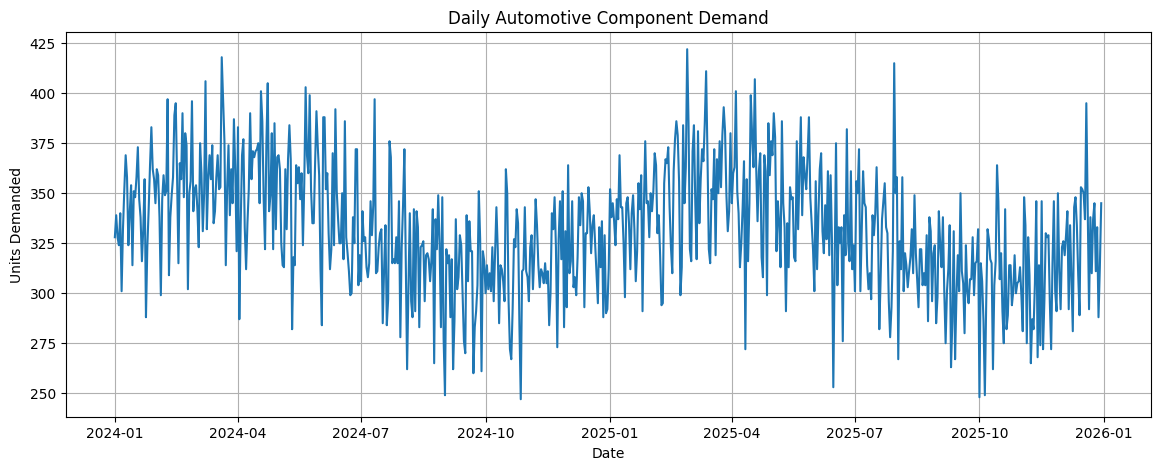

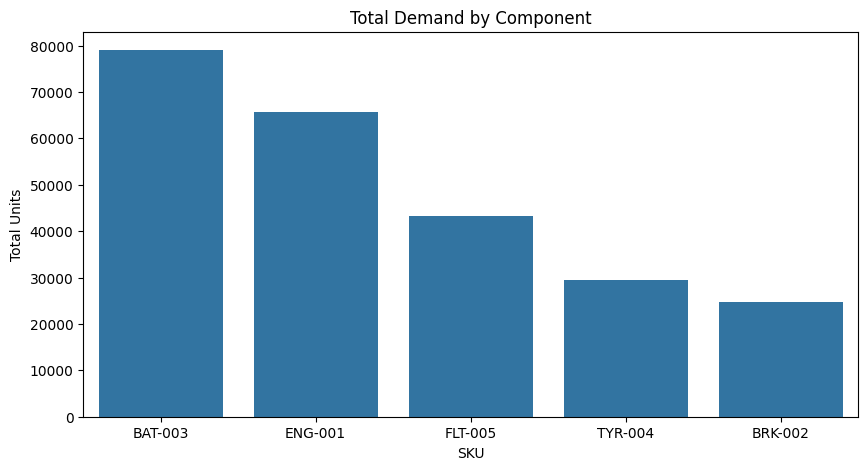

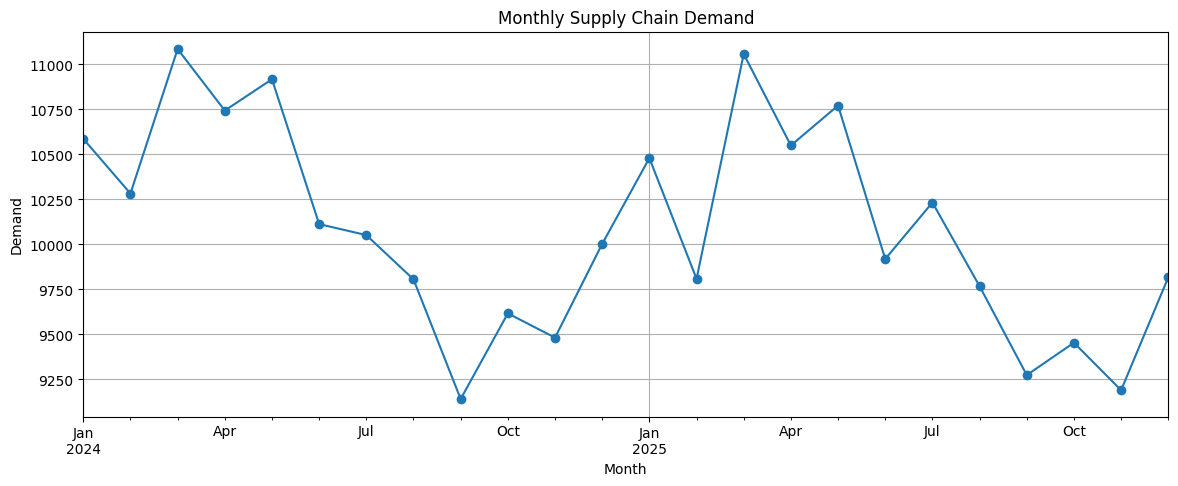

EDA COMPLETED


In [4]:

# ============================================================
# SECTION 4: EXPLORATORY DATA ANALYSIS
# ============================================================

# 1. Total demand by component

component_demand = (
    demand_history.groupby("sku_id")["units_demanded"]
    .sum()
    .sort_values(ascending=False)
)

print("TOTAL DEMAND BY COMPONENT")
display(component_demand)

# 2. Daily demand trend

daily_demand = (
    demand_history.groupby("date")["units_demanded"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Daily Automotive Component Demand")
plt.xlabel("Date")
plt.ylabel("Units Demanded")
plt.grid(True)
plt.show()

# 3. Demand by component

plt.figure(figsize=(10, 5))
sns.barplot(
    x=component_demand.index,
    y=component_demand.values
)
plt.title("Total Demand by Component")
plt.xlabel("SKU")
plt.ylabel("Total Units")
plt.show()

# 4. Monthly demand

demand_history["month"] = (
    demand_history["date"].dt.to_period("M")
)

monthly_demand = (
    demand_history.groupby("month")["units_demanded"]
    .sum()
)

monthly_demand.plot(figsize=(14, 5), marker="o")
plt.title("Monthly Supply Chain Demand")
plt.xlabel("Month")
plt.ylabel("Demand")
plt.grid(True)
plt.show()

print("EDA COMPLETED")


In [6]:

# ============================================================
# SECTION 5: FEATURE ENGINEERING
# ============================================================

demand_history = demand_history.sort_values(
    ["sku_id", "date"]
).copy()

# Calendar features

demand_history["day_of_week"] = (
    demand_history["date"].dt.dayofweek
)

demand_history["month"] = (
    demand_history["date"].dt.month
)

demand_history["day_of_year"] = (
    demand_history["date"].dt.dayofyear
)

demand_history["is_weekend"] = (
    demand_history["day_of_week"] >= 5
).astype(int)

# Historical demand features

grouped = demand_history.groupby("sku_id")["units_demanded"]

demand_history["lag_1"] = grouped.shift(1)
demand_history["lag_7"] = grouped.shift(7)

demand_history["rolling_mean_7"] = (
    demand_history.groupby("sku_id")["units_demanded"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

demand_history["rolling_mean_30"] = (
    demand_history.groupby("sku_id")["units_demanded"]
    .transform(lambda x: x.shift(1).rolling(30).mean())
)

# Remove rows with missing lag and rolling values

model_data = demand_history.dropna().copy()

print("FEATURE ENGINEERING COMPLETED")
print("Original rows:", len(demand_history))
print("Model rows:", len(model_data))

display(model_data.head())



# ============================================================
# SECTION 6: RANDOM FOREST MODEL TRAINING
# ============================================================

features = [
    "sku_id",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_mean_7",
    "rolling_mean_30"
]

target = "units_demanded"

# Chronological split: final 90 days for testing

cutoff_date = model_data["date"].max() - pd.Timedelta(days=89)

train_data = model_data[
    model_data["date"] < cutoff_date
].copy()

test_data = model_data[
    model_data["date"] >= cutoff_date
].copy()

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

# Preprocessing

categorical_features = ["sku_id"]

numerical_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "sku",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

# Random Forest pipeline

forecast_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            random_state=42,
            n_jobs=-1
        )
    )
])

forecast_model.fit(X_train, y_train)

predictions = forecast_model.predict(X_test)

print("RANDOM FOREST MODEL TRAINED")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


FEATURE ENGINEERING COMPLETED
Original rows: 3650
Model rows: 3500


,date,sku_id,component_name,plant_id,units_demanded,unit_price,promotion_flag,production_plan,month,day_of_week,day_of_year,is_weekend,lag_1,lag_7,rolling_mean_7,rolling_mean_30
1490,2024-01-31,BAT-003,Battery Component,PLANT-01,117,3500,0,112,1,2,31,0,115.0,93.0,110.000000,110.400000
1491,2024-02-01,BAT-003,Battery Component,PLANT-01,115,3500,0,113,2,3,32,0,117.0,95.0,113.428571,110.166667
1492,2024-02-02,BAT-003,Battery Component,PLANT-01,107,3500,0,91,2,4,33,0,115.0,114.0,116.285714,110.266667
1493,2024-02-03,BAT-003,Battery Component,PLANT-01,120,3500,1,105,2,5,34,1,107.0,117.0,115.285714,110.433333
1494,2024-02-04,BAT-003,Battery Component,PLANT-01,107,3500,0,103,2,6,35,1,120.0,123.0,115.714286,110.666667


RANDOM FOREST MODEL TRAINED
Training rows: 3050
Testing rows: 450


In [7]:

# ============================================================
# SECTION 7: MODEL EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

wape = (
    np.sum(np.abs(y_test - predictions))
    / np.sum(np.abs(y_test))
) * 100

# Weekly baseline: predict using lag_7

baseline_predictions = X_test["lag_7"].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_wape = (
    np.sum(np.abs(y_test.values - baseline_predictions))
    / np.sum(np.abs(y_test.values))
) * 100

evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "WAPE"],
    "Random Forest": [mae, rmse, wape],
    "Weekly Baseline": [
        baseline_mae,
        baseline_rmse,
        baseline_wape
    ]
})

display(evaluation_results)

print("MODEL EVALUATION COMPLETED")


,Metric,Random Forest,Weekly Baseline
0,MAE,8.738442,11.508889
1,RMSE,10.987008,14.435989
2,WAPE,13.937897,18.356786


MODEL EVALUATION COMPLETED


In [8]:

# ============================================================
# SECTION 8: 30-DAY FUTURE DEMAND FORECAST
# ============================================================

def forecast_future_demand(sku, history, days=30):

    sku_history = (
        history[history["sku_id"] == sku]
        .sort_values("date")
        .copy()
    )

    future_predictions = []

    future_date = sku_history["date"].max() + pd.Timedelta(days=1)

    for _ in range(days):

        values = sku_history["units_demanded"].values

        next_row = pd.DataFrame([{
            "sku_id": sku,
            "day_of_week": future_date.dayofweek,
            "month": future_date.month,
            "day_of_year": future_date.dayofyear,
            "is_weekend": int(future_date.dayofweek >= 5),
            "lag_1": values[-1],
            "lag_7": values[-7],
            "rolling_mean_7": np.mean(values[-7:]),
            "rolling_mean_30": np.mean(values[-30:])
        }])

        prediction = max(
            0,
            float(forecast_model.predict(next_row)[0])
        )

        future_predictions.append({
            "date": future_date,
            "sku_id": sku,
            "predicted_demand": prediction
        })

        new_row = pd.DataFrame([{
            "date": future_date,
            "sku_id": sku,
            "units_demanded": prediction
        }])

        sku_history = pd.concat(
            [sku_history, new_row],
            ignore_index=True
        )

        future_date += pd.Timedelta(days=1)

    return future_predictions


forecast_records = []

for sku in products.keys():
    forecast_records.extend(
        forecast_future_demand(
            sku,
            demand_history,
            days=30
        )
    )

forecast_df = pd.DataFrame(forecast_records)

print("30-DAY FORECAST COMPLETED")
print("Forecast shape:", forecast_df.shape)

display(forecast_df.head(10))


30-DAY FORECAST COMPLETED
Forecast shape: (150, 3)


,date,sku_id,predicted_demand
0,2025-12-31,ENG-001,89.601998
1,2026-01-01,ENG-001,99.921314
2,2026-01-02,ENG-001,100.906997
3,2026-01-03,ENG-001,88.507149
4,2026-01-04,ENG-001,85.855084
5,2026-01-05,ENG-001,93.599262
6,2026-01-06,ENG-001,89.125750
7,2026-01-07,ENG-001,91.165919
8,2026-01-08,ENG-001,91.576051
9,2026-01-09,ENG-001,95.267947


In [9]:

# ============================================================
# SECTION 9: INVENTORY OPTIMIZATION
# ============================================================

Z_SCORE = 1.645
REVIEW_PERIOD = 7

inventory_records = []

for _, item in inventory.iterrows():

    sku = item["sku_id"]

    supplier = supplier_df[
        supplier_df["sku_id"] == sku
    ].iloc[0]

    sku_forecast = (
        forecast_df[forecast_df["sku_id"] == sku]
        .sort_values("date")
    )

    lead_time = int(supplier["lead_time_days"])

    forecast_values = (
        sku_forecast["predicted_demand"].values
    )

    # Inventory position

    inventory_position = (
        item["on_hand"]
        + item["on_order"]
        - item["backorders"]
    )

    # Lead-time demand

    lead_time_demand = forecast_values[:lead_time].sum()

    # Forecast error standard deviation
    # Use only the corresponding SKU's held-out predictions.

    sku_test = test_data[test_data["sku_id"] == sku].copy()

    sku_test["prediction"] = forecast_model.predict(
        sku_test[features]
    )

    forecast_error_std = np.std(
        sku_test["units_demanded"] - sku_test["prediction"],
        ddof=1
    )

    safety_stock = (
        Z_SCORE
        * forecast_error_std
        * np.sqrt(lead_time)
    )

    reorder_point = lead_time_demand + safety_stock

    target_stock = (
        lead_time_demand
        + forecast_values[lead_time:lead_time + REVIEW_PERIOD].sum()
        + safety_stock
    )

    # Order quantity

    if inventory_position < reorder_point:

        raw_order_qty = max(
            supplier["min_order_qty"],
            target_stock - inventory_position
        )

        pack_size = int(supplier["pack_size"])

        recommended_order_qty = (
            np.ceil(raw_order_qty / pack_size)
            * pack_size
        )

        order_status = "REORDER"

    else:
        recommended_order_qty = 0
        order_status = "SUFFICIENT STOCK"

    inventory_records.append({
        "sku_id": sku,
        "inventory_position": inventory_position,
        "lead_time_demand": lead_time_demand,
        "safety_stock": safety_stock,
        "reorder_point": reorder_point,
        "target_stock": target_stock,
        "recommended_order_qty": recommended_order_qty,
        "order_status": order_status
    })


inventory_results = pd.DataFrame(inventory_records)

print("INVENTORY OPTIMIZATION COMPLETED")
display(inventory_results)

print(
    "Total recommended replenishment:",
    inventory_results["recommended_order_qty"].sum()
)


INVENTORY OPTIMIZATION COMPLETED


,sku_id,inventory_position,lead_time_demand,safety_stock,reorder_point,target_stock,recommended_order_qty,order_status
0,ENG-001,680,1100.145804,56.399595,1156.545399,1798.083074,1120.0,REORDER
1,BRK-002,440,276.138051,55.271605,331.409656,590.838308,0.0,SUFFICIENT STOCK
2,BAT-003,720,1662.601642,65.289920,1727.891562,2500.673243,1790.0,REORDER
3,TYR-004,585,401.639778,58.696592,460.336370,758.923946,0.0,SUFFICIENT STOCK
4,FLT-005,345,418.348944,46.678747,465.027691,889.993639,545.0,REORDER


Total recommended replenishment: 3455.0


In [10]:

# ============================================================
# SECTION 10: SUPPLIER PERFORMANCE
# ============================================================

supplier_analysis = purchase_orders.copy()

supplier_analysis["delivery_delay_days"] = (
    supplier_analysis["actual_date"]
    - supplier_analysis["expected_date"]
).dt.days

supplier_analysis["on_time"] = (
    supplier_analysis["delivery_delay_days"] <= 0
).astype(int)

supplier_analysis["fulfilment_percentage"] = (
    supplier_analysis["received_qty"]
    / supplier_analysis["ordered_qty"]
) * 100

supplier_summary = (
    supplier_analysis.groupby("supplier_id")
    .agg(
        total_orders=("po_id", "count"),
        average_delay_days=("delivery_delay_days", "mean"),
        on_time_rate=("on_time", "mean"),
        average_fulfilment=("fulfilment_percentage", "mean")
    )
    .reset_index()
)

supplier_summary["on_time_rate"] *= 100

supplier_summary = supplier_summary.merge(
    supplier_df[["supplier_id", "supplier_name", "reliability_score"]],
    on="supplier_id",
    how="left"
)

print("SUPPLIER PERFORMANCE COMPLETED")
display(supplier_summary)


SUPPLIER PERFORMANCE COMPLETED


,supplier_id,total_orders,average_delay_days,on_time_rate,average_fulfilment,supplier_name,reliability_score
0,SUP-01,1,1.0,0.0,100.000000,AutoParts India,0.95
1,SUP-02,1,0.0,100.0,100.000000,Prime Components,0.91
2,SUP-03,1,2.0,0.0,93.333333,Global Battery Co,0.88
3,SUP-04,1,0.0,100.0,100.000000,RoadGrip Suppliers,0.94
4,SUP-05,1,-1.0,100.0,100.000000,FilterTech,0.97


In [17]:

import os

# Find the actual uploaded PDF filenames
quality_pdf = "Supplier Quality Manual.pdf"
logistics_options = [
    "Supplier Logistics Manual.pdf",
    "Supplier Logistics Manual (1).pdf"
]

if not os.path.exists(quality_pdf):
    raise FileNotFoundError("Supplier Quality Manual.pdf not found.")

logistics_pdf = next(
    (name for name in logistics_options if os.path.exists(name)),
    None
)

if logistics_pdf is None:
    raise FileNotFoundError("Supplier Logistics Manual PDF not found.")

required_pdfs = [quality_pdf, logistics_pdf]

print("Both PDF files are available!")
print("Quality Manual:", quality_pdf)
print("Logistics Manual:", logistics_pdf)




Both PDF files are available!
Quality Manual: Supplier Quality Manual.pdf
Logistics Manual: Supplier Logistics Manual.pdf


In [18]:
from pypdf import PdfReader

documents = {}

for filename in required_pdfs:
    reader = PdfReader(filename)

    pages = []

    for page_number, page in enumerate(reader.pages, start=1):
        text = page.extract_text() or ""

        pages.append({
            "page": page_number,
            "text": text
        })

    documents[filename] = pages

    print(f"\nFile: {filename}")
    print(f"Total pages: {len(pages)}")
    print(f"Extracted characters: {sum(len(p['text']) for p in pages)}")

print("\nPDF text extraction completed!")


File: Supplier Quality Manual.pdf
Total pages: 17
Extracted characters: 40745

File: Supplier Logistics Manual.pdf
Total pages: 16
Extracted characters: 29453

PDF text extraction completed!


In [21]:

# ==========================================
# CREATE TEXT CHUNKS FROM BOTH PDF MANUALS
# ==========================================

supplier_chunks = []

CHUNK_SIZE = 180
OVERLAP = 30

for filename, pages in documents.items():

    for page_data in pages:

        words = page_data["text"].split()

        start = 0

        while start < len(words):

            end = start + CHUNK_SIZE
            chunk_words = words[start:end]

            if chunk_words:
                supplier_chunks.append({
                    "source": filename,
                    "page": page_data["page"],
                    "text": " ".join(chunk_words)
                })

            start += CHUNK_SIZE - OVERLAP

print("Text chunking completed!")
print("Total chunks:", len(supplier_chunks))

print("\nFirst chunk:")
print(supplier_chunks[0]["text"][:500])


Text chunking completed!
Total chunks: 86

First chunk:
SUPPLIER QUALITY MANUAL MARCH 2023


In [22]:

# ============================================================
# SECTION 12: RAG EMBEDDINGS AND RETRIEVAL
# ============================================================

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

chunk_texts = [
    item["text"] for item in supplier_chunks
]

embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
).astype("float32")

embedding_dimension = embeddings.shape[1]

supplier_index = faiss.IndexFlatIP(
    embedding_dimension
)

supplier_index.add(embeddings)


# Retrieve relevant passages

def retrieve_documents(question, top_k=5):

    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = supplier_index.search(
        query_embedding,
        min(top_k, len(supplier_chunks))
    )

    results = []

    for score, index in zip(scores[0], indices[0]):

        if index < 0:
            continue

        result = supplier_chunks[index].copy()
        result["similarity_score"] = float(score)

        results.append(result)

    return results


# Create context

def create_context(results):

    context = ""

    for result in results:

        context += (
            f"\nSource: {result['source']}"
            f"\nPage: {result['page']}"
            f"\nContent: {result['text']}\n"
        )

    return context


# Test retrieval

test_results = retrieve_documents(
    "What are the supplier delivery and quality requirements?",
    top_k=5
)

print("RAG RETRIEVAL COMPLETED")

for result in test_results:
    print("\nSource:", result["source"])
    print("Page:", result["page"])
    print("Similarity:", round(result["similarity_score"], 3))
    print("Text:", result["text"][:300])


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

RAG RETRIEVAL COMPLETED

Source: Supplier Quality Manual.pdf
Page: 7
Similarity: 0.606
Text: KONGSBERG AUTOMOTIVE GROUP – SUPPLIER QUALITY MANUAL M A R C H 2 0 2 3 / 7 SECTION 3: SUPPLIER SELECTION AND MONITORING 3 . 1 S U P P L I E R A S S E S S M E N T A N D S E L E C T I O N Kongsberg Automotive’s supply base shall consist of organizations supportive of our business needs. Kongsberg Auto

Source: Supplier Quality Manual.pdf
Page: 1
Similarity: 0.59
Text: SUPPLIER QUALITY MANUAL MARCH 2023

Source: Supplier Logistics Manual.pdf
Page: 3
Similarity: 0.586
Text: requirements presented in this document and all related documents, are provided as a complement to, and do not replace or alter any Purchase Agreement, the Kongsberg Automotive General Purchasing Conditions (KA GPC), Supplier Quality Manual, or requirements included in applicable engineering drawing

Source: Supplier Logistics Manual.pdf
Page: 3
Similarity: 0.586
Text: KONGSBERG AUTOMOTIVE GROUP // SUPPLIER LOGISTICS MANUAL 3 PR

In [25]:

# ============================================================
# SECTION 13: FOUNDRY RAG ASSISTANT
# ============================================================

from google.colab import userdata

endpoint = (
    "https://rubeenashaikds-8633-resource.services.ai.azure.com/openai/v1"
)

deployment_name = "gpt-5-mini"

api_key = userdata.get("FOUNDRY_API_KEY")

if not api_key:
    raise ValueError("FOUNDRY_API_KEY is missing")

client = OpenAI(
    base_url=endpoint,
    api_key=api_key
)


def ask_supplier_assistant(question, top_k=5):

    results = retrieve_documents(
        question,
        top_k=top_k
    )

    context = create_context(results)

    prompt = f"""
You are a supplier policy assistant.

Answer using only the supplied document passages.

If the answer is not available, say so clearly.
Do not invent supplier requirements.
Mention the source document and page numbers.

DOCUMENT PASSAGES:
{context}

QUESTION:
{question}
"""

    response = client.responses.create(
        model=deployment_name,
        input=prompt
    )

    return {
        "answer": response.output_text,
        "sources": [
            {
                "source": r["source"],
                "page": r["page"],
                "similarity_score": r["similarity_score"]
            }
            for r in results
        ]
    }


print("RAG ASSISTANT READY")
print("No Foundry request made yet.")


RAG ASSISTANT READY
No Foundry request made yet.


In [26]:

# ============================================================
# SECTION 14: INTEGRATED RECOMMENDATIONS
# ============================================================

integrated_results = inventory_results.merge(
    supplier_df[
        [
            "sku_id",
            "supplier_id",
            "supplier_name",
            "lead_time_days",
            "reliability_score"
        ]
    ],
    on="sku_id",
    how="left"
)

integrated_results = integrated_results.merge(
    supplier_summary[
        [
            "supplier_id",
            "total_orders",
            "average_delay_days",
            "on_time_rate",
            "average_fulfilment"
        ]
    ],
    on="supplier_id",
    how="left"
)


def generate_recommendations(data):

    recommendations = []

    for _, row in data.iterrows():

        if row["order_status"] == "REORDER":

            action = (
                f"Review replenishment of "
                f"{row['recommended_order_qty']:.0f} units "
                f"for {row['sku_id']}."
            )

        else:

            action = (
                f"Stock is currently above the reorder point "
                f"for {row['sku_id']}. Continue monitoring."
            )

        if (
            row["on_time_rate"] < 100
            or row["average_fulfilment"] < 100
        ):

            supplier_action = (
                "Review supplier delivery and fulfilment performance."
            )

        else:

            supplier_action = (
                "Observed delivery performance acceptable "
                "in the available sample."
            )

        recommendations.append({
            "sku_id": row["sku_id"],
            "supplier_name": row["supplier_name"],
            "inventory_action": action,
            "supplier_action": supplier_action
        })

    return pd.DataFrame(recommendations)


recommendations_df = generate_recommendations(
    integrated_results
)

display(recommendations_df)

print("INTEGRATED RECOMMENDATIONS COMPLETED")


,sku_id,supplier_name,inventory_action,supplier_action
0,ENG-001,AutoParts India,Review replenishment of 1120 units for ENG-001.,Review supplier delivery and fulfilment perfor...
1,BRK-002,Prime Components,Stock is currently above the reorder point for...,Observed delivery performance acceptable in th...
2,BAT-003,Global Battery Co,Review replenishment of 1790 units for BAT-003.,Review supplier delivery and fulfilment perfor...
3,TYR-004,RoadGrip Suppliers,Stock is currently above the reorder point for...,Observed delivery performance acceptable in th...
4,FLT-005,FilterTech,Review replenishment of 545 units for FLT-005.,Observed delivery performance acceptable in th...


INTEGRATED RECOMMENDATIONS COMPLETED


In [27]:

# ============================================================
# SECTION 15: PYTHON AGENT TOOLS
# ============================================================

def demand_forecast_tool(sku_id=None):

    data = forecast_df.copy()

    if sku_id:
        data = data[data["sku_id"] == sku_id]

    return data.to_dict(orient="records")


def inventory_tool(sku_id=None):

    data = inventory_results.copy()

    if sku_id:
        data = data[data["sku_id"] == sku_id]

    return data.to_dict(orient="records")


def supplier_performance_tool(sku_id=None):

    data = supplier_summary.copy()

    if sku_id:

        mapping = supplier_df[
            ["supplier_id", "sku_id"]
        ].drop_duplicates()

        data = data.merge(
            mapping,
            on="supplier_id",
            how="left"
        )

        data = data[data["sku_id"] == sku_id]

    return data.to_dict(orient="records")


def supplier_rag_tool(question):

    return ask_supplier_assistant(question)


def supply_chain_overview_tool():

    return {
        "total_components": len(inventory_results),
        "components_requiring_reorder": int(
            (inventory_results["order_status"] == "REORDER").sum()
        ),
        "total_recommended_order_units": float(
            inventory_results["recommended_order_qty"].sum()
        ),
        "total_suppliers": int(
            supplier_df["supplier_id"].nunique()
        )
    }


agent_tools = {
    "demand_forecast": demand_forecast_tool,
    "inventory": inventory_tool,
    "supplier_performance": supplier_performance_tool,
    "supplier_documents": supplier_rag_tool,
    "supply_chain_overview": supply_chain_overview_tool
}

print("FIVE PYTHON AGENT TOOLS REGISTERED")

for name in agent_tools:
    print(name)


FIVE PYTHON AGENT TOOLS REGISTERED
demand_forecast
inventory
supplier_performance
supplier_documents
supply_chain_overview


In [28]:

# ============================================================
# SECTION 16: MICROSOFT FOUNDRY AGENT
# ============================================================

foundry_tools = [
    {
        "type": "function",
        "name": "demand_forecast",
        "description": "Retrieve demand forecasts.",
        "parameters": {
            "type": "object",
            "properties": {
                "sku_id": {"type": ["string", "null"]}
            },
            "required": ["sku_id"],
            "additionalProperties": False
        }
    },
    {
        "type": "function",
        "name": "inventory",
        "description": "Retrieve inventory and reorder recommendations.",
        "parameters": {
            "type": "object",
            "properties": {
                "sku_id": {"type": ["string", "null"]}
            },
            "required": ["sku_id"],
            "additionalProperties": False
        }
    },
    {
        "type": "function",
        "name": "supplier_performance",
        "description": "Retrieve supplier performance.",
        "parameters": {
            "type": "object",
            "properties": {
                "sku_id": {"type": ["string", "null"]}
            },
            "required": ["sku_id"],
            "additionalProperties": False
        }
    },
    {
        "type": "function",
        "name": "supplier_documents",
        "description": "Retrieve supplier manual passages using RAG.",
        "parameters": {
            "type": "object",
            "properties": {
                "question": {"type": "string"}
            },
            "required": ["question"],
            "additionalProperties": False
        }
    },
    {
        "type": "function",
        "name": "supply_chain_overview",
        "description": "Retrieve overall supply-chain metrics.",
        "parameters": {
            "type": "object",
            "properties": {},
            "required": [],
            "additionalProperties": False
        }
    }
]


def execute_foundry_tool(name, arguments):

    if name not in agent_tools:
        return {"error": "Unknown tool"}

    try:
        return agent_tools[name](**arguments)

    except Exception as error:
        return {"error": str(error)}


def foundry_supply_chain_agent(question):

    instructions = """
    You are an automotive manufacturing supply-chain assistant.

    Use Python tools for all numerical calculations.
    Use RAG for supplier policy evidence.
    Do not invent data.
    Clearly identify missing information.
    All project data is synthetic.
    Do not create purchase orders or contact suppliers.
    """

    response = client.responses.create(
        model=deployment_name,
        instructions=instructions,
        input=question,
        tools=foundry_tools,
        tool_choice="auto"
    )

    for step in range(8):

        function_calls = [
            item for item in response.output
            if item.type == "function_call"
        ]

        if not function_calls:
            break

        tool_outputs = []

        for call in function_calls:

            arguments = json.loads(call.arguments)

            print("Selected tool:", call.name)

            result = execute_foundry_tool(
                call.name,
                arguments
            )

            tool_outputs.append({
                "type": "function_call_output",
                "call_id": call.call_id,
                "output": json.dumps(result, default=str)
            })

        response = client.responses.create(
            model=deployment_name,
            instructions=instructions,
            previous_response_id=response.id,
            input=tool_outputs,
            tools=foundry_tools,
            tool_choice="auto"
        )

    return response.output_text


print("FOUNDRY AGENT READY")


FOUNDRY AGENT READY


In [29]:

# ============================================================
# SECTION 17: AGENT TESTING
# ============================================================

test_question = """
Analyze ENG-001.

Check its demand forecast, inventory position,
supplier performance and relevant supplier
quality and delivery requirements.

Provide an evidence-based recommendation.
"""

agent_answer = foundry_supply_chain_agent(
    test_question
)

print("=" * 60)
print("FOUNDRY GPT-5-MINI AGENT RESPONSE")
print("=" * 60)

print(agent_answer)


Selected tool: demand_forecast
Selected tool: inventory
Selected tool: supplier_performance
Selected tool: supplier_documents
FOUNDRY GPT-5-MINI AGENT RESPONSE
Summary (SKU: ENG-001)
- Forecast (30-day window provided): average daily demand ≈ 92.32 units/day (30-day mean).
- Current inventory position: on-hand = 680 units.
- Calculated coverage: on-hand covers ≈ 7.4 days of forecasted demand (680 ÷ 92.32 ≈ 7.37 days).
- Inventory targets from system:
  - Lead-time demand = 1,100.15 units
  - Safety stock = 56.40 units
  - Reorder point (ROP) = 1,156.55 units
  - Target stock = 1,798.08 units
  - System recommended order qty = 1,120 units (order status = REORDER)
- Implied supplier lead time (from lead-time demand): ≈ 11.91 days (1,100.15 ÷ 92.32 ≈ 11.91 days).

Key observations and calculations
- Forecast average: sum of daily forecasts over the 30-day series = 2,769.64 units → mean = 2,769.64 ÷ 30 = 92.32 units/day.
- Inventory shortfall relative to ROP: ROP − on-hand = 1,156.55 − 680

In [30]:

# ============================================================
# SECTION 18: SAVE PROJECT OUTPUTS
# ============================================================

import os
import pickle
import json

os.makedirs("supply_chain_ai_outputs", exist_ok=True)

output_folder = "supply_chain_ai_outputs"

# Save datasets and results

csv_outputs = {
    "demand_history.csv": demand_history,
    "forecast_results.csv": forecast_df,
    "inventory_results.csv": inventory_results,
    "supplier_performance.csv": supplier_summary,
    "integrated_recommendations.csv": recommendations_df
}

for filename, dataframe in csv_outputs.items():

    dataframe.to_csv(
        os.path.join(output_folder, filename),
        index=False
    )


# Save trained ML pipeline

with open(
    os.path.join(output_folder, "forecast_model.pkl"),
    "wb"
) as file:

    pickle.dump(forecast_model, file)


# Save RAG index and chunks

faiss.write_index(
    supplier_index,
    os.path.join(output_folder, "supplier_index.faiss")
)

with open(
    os.path.join(output_folder, "supplier_chunks.pkl"),
    "wb"
) as file:

    pickle.dump(supplier_chunks, file)


# Save project configuration

config = {
    "project": "Automotive Supply Chain AI",
    "model": "Random Forest Regressor",
    "forecast_horizon_days": 30,
    "embedding_model": "all-MiniLM-L6-v2",
    "llm_deployment": deployment_name,
    "data_type": "Synthetic"
}

with open(
    os.path.join(output_folder, "config.json"),
    "w"
) as file:

    json.dump(config, file, indent=4)


# Save agent response if available

if "agent_answer" in globals():

    with open(
        os.path.join(output_folder, "agent_response.txt"),
        "w"
    ) as file:

        file.write(agent_answer)


print("PROJECT OUTPUTS SAVED")
print("Folder:", output_folder)
print("Files:", os.listdir(output_folder))


PROJECT OUTPUTS SAVED
Folder: supply_chain_ai_outputs
Files: ['supplier_performance.csv', 'supplier_chunks.pkl', 'forecast_results.csv', 'demand_history.csv', 'agent_response.txt', 'forecast_model.pkl', 'supplier_index.faiss', 'config.json', 'integrated_recommendations.csv', 'inventory_results.csv']
